# Karatsuba Multiplication: Simple Comparison

## Aim
Compare three methods for multiplying large integers:

1. **Brute force:** multiply every pair of decimal digits.
2. **Divide-and-conquer:** Karatsuba's algorithm.
3. **Built-in:** Python's `x * y`.

## Mathematics
Choose $m$ and write

$$x=a10^m+b, \qquad y=c10^m+d.$$

Then

$$xy=ac10^{2m}+(ad+bc)10^m+bd.$$

Karatsuba computes only three smaller products:

$$p=ac, \qquad q=bd, \qquad r=(a+b)(c+d).$$

Since

$$r-p-q=ad+bc,$$

we obtain

$$\boxed{xy=p10^{2m}+(r-p-q)10^m+q.}$$

Brute force uses approximately $n^2$ digit multiplications. Karatsuba satisfies

$$T(n)=3T(n/2)+\Theta(n),$$

so

$$T(n)=\Theta\left(n^{\log_2 3}\right)\approx\Theta(n^{1.585}).$$


## Before running the code

The code defines all three methods, checks that they return the same product, measures the **mean execution time**, and draws:

- a time comparison graph;
- a speedup graph relative to brute force.


In [1]:
import random, time, statistics
import matplotlib.pyplot as plt

SEED=20260907
DIGIT_SIZES=[8,16,32,64,128,256,512]
REPEATS=3 # Number of times a function is run on the given input to compute the average time
CUTOFF=32 
rng=random.Random(SEED)

def brute_force(x, y):

    # Base case: multiply single-digit integers directly
    if x < 10 or y < 10:
        return x * y

    # Find the maximum number of digits
    n = max(len(str(x)), len(str(y)))

    # Divide the integers approximately into equal halves
    m = n // 2

    # 10^m is used to split the integers
    power = 10 ** m

    # x = a(10^m) + b
    a, b = divmod(x, power)

    # y = c(10^m) + d
    c, d = divmod(y, power)

    # Compute the four smaller products
    ac = brute_force(a, c)
    ad = brute_force(a, d)
    bc = brute_force(b, c)
    bd = brute_force(b, d)

    # Reconstruct the final product
    product = (
        ac * 10 ** (2 * m)
        + (ad + bc) * 10 ** m
        + bd
    )

    return product

def karatsuba(x,y,cutoff=CUTOFF): # CUTOFF is the threshold below which recursion stops and x*y is computed directly
    n=max(len(str(x)),len(str(y)))
    if n<=cutoff: return x*y
    m=n//2; power=10**m
    a,b=divmod(x,power); # quotient and remainder when x is divided by power
    c,d=divmod(y,power); # quotient and remainder when y is divided by power
    p=karatsuba(a,c,cutoff)
    q=karatsuba(b,d,cutoff)
    r=karatsuba(a+b,c+d,cutoff)
    return p*10**(2*m)+(r-p-q)*power+q

def mean_time(f,x,y,repeats=REPEATS):
    values=[]; answer=None
    for _ in range(repeats):
        start=time.perf_counter(); answer=f(x,y); values.append(time.perf_counter()-start)
    return statistics.mean(values),answer


In [2]:
rows=[]
for n in DIGIT_SIZES:
    x=rng.randint(10**(n-1),10**n-1); y=rng.randint(10**(n-1),10**n-1)
    tb,z1=mean_time(brute_force,x,y)
    tk,z2=mean_time(karatsuba,x,y)
    tp,z3=mean_time(lambda u,v:u*v,x,y)
    assert z1==z2==z3
    rows.append((n,tb,tk,tp))
    print(f'{n:4d} digits: brute={tb:.6e}, Karatsuba={tk:.6e}, built-in={tp:.6e}')


   8 digits: brute=9.393333e-05, Karatsuba=3.166667e-06, built-in=7.666667e-07
  16 digits: brute=2.982667e-04, Karatsuba=2.600000e-06, built-in=8.333333e-07
  32 digits: brute=1.497800e-03, Karatsuba=3.233333e-06, built-in=8.666667e-07
  64 digits: brute=4.392367e-03, Karatsuba=1.146667e-05, built-in=5.333333e-07
 128 digits: brute=8.049967e-03, Karatsuba=3.030000e-05, built-in=6.666667e-07
 256 digits: brute=2.827630e-02, Karatsuba=1.150333e-04, built-in=1.200000e-06
 512 digits: brute=1.140214e-01, Karatsuba=2.988333e-04, built-in=3.366667e-06


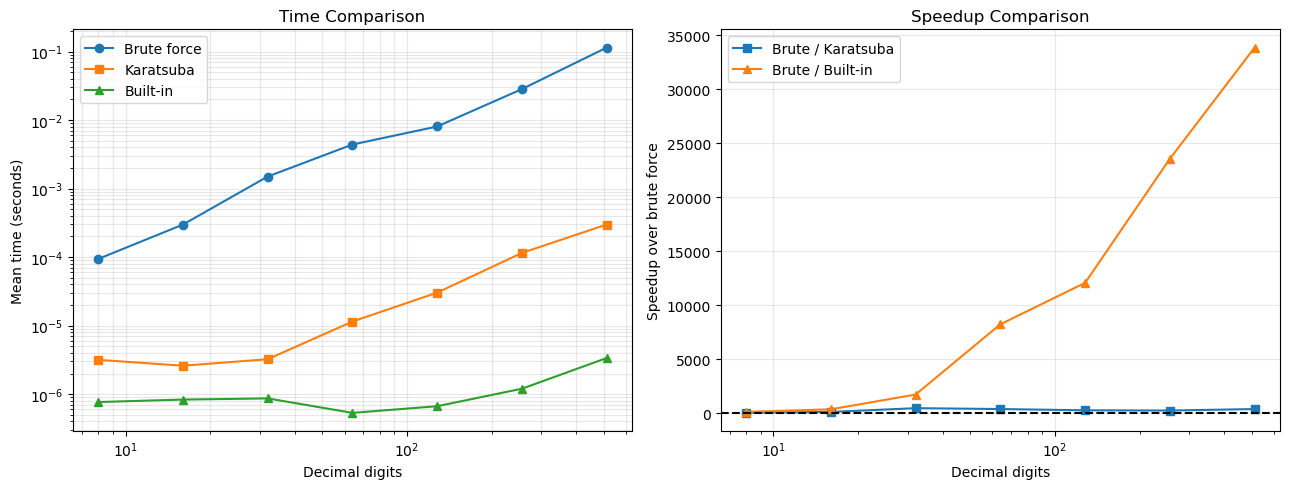

In [3]:
n=[r[0] for r in rows]; tb=[r[1] for r in rows]; tk=[r[2] for r in rows]; tp=[r[3] for r in rows]
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].loglog(n,tb,'o-',label='Brute force'); ax[0].loglog(n,tk,'s-',label='Karatsuba'); ax[0].loglog(n,tp,'^-',label='Built-in')
ax[0].set(xlabel='Decimal digits',ylabel='Mean time (seconds)',title='Time Comparison'); ax[0].grid(True,which='both',alpha=.3); ax[0].legend()
ax[1].semilogx(n,[b/k for b,k in zip(tb,tk)],'s-',label='Brute / Karatsuba'); ax[1].semilogx(n,[b/p for b,p in zip(tb,tp)],'^-',label='Brute / Built-in')
ax[1].axhline(1,color='black',ls='--'); ax[1].set(xlabel='Decimal digits',ylabel='Speedup over brute force',title='Speedup Comparison'); ax[1].grid(True,alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()


### Meaning of the graphs

- In the **time graph**, the lowest curve represents the fastest method.
- In the **speedup graph**, a value of $2500$ means that Karatsuba is 2500 times faster than brute force integer multiplication.
- Karatsuba may be slower for small inputs because recursive calls and splitting add overhead.
- The built-in method is usually fastest because its arithmetic is implemented in optimized compiled code.


## Two exercises

### Exercise 1: Verify the identity
For $x=1234$ and $y=5678$, take $m=2$. Write code to print $a,b,c,d,p,q,r$ and verify

$$xy=p10^{2m}+(r-p-q)10^m+q.$$

### Exercise 2: Find the faster method
For 32, 64, 128 and 256 digits, compute the mean times of brute force and Karatsuba. Plot both and print $t_B/t_K$. State where this ratio is greater than $1$.


## Solution 1

In [5]:
x, y, m = 1234, 5678, 2
power = 10 ** m

a, b = divmod(x, power)
c, d = divmod(y, power)

p = a * c
q = b * d
r = (a + b) * (c + d)

rhs = p * (10 ** (2 * m)) + (r - p - q) * (10 ** m) + q

print(f"a={a}, b={b}, c={c}, d={d}")
print(f"p={p}, q={q}, r={r}")
print(f"Computed xy: {x * y}")
print(f"Verified identity result: {rhs}")

a=12, b=34, c=56, d=78
p=672, q=2652, r=6164
Computed xy: 7006652
Verified identity result: 7006652


## Solution 2

 32 digits | Brute: 4.376667e-04s | Karatsuba: 1.266667e-06s | Ratio (t_B/t_K): 345.53
  -> Ratio is greater than 1 for 32 digits.
 64 digits | Brute: 2.379900e-03s | Karatsuba: 9.333333e-06s | Ratio (t_B/t_K): 254.99
  -> Ratio is greater than 1 for 64 digits.
128 digits | Brute: 6.846533e-03s | Karatsuba: 3.030000e-05s | Ratio (t_B/t_K): 225.96
  -> Ratio is greater than 1 for 128 digits.
256 digits | Brute: 2.871170e-02s | Karatsuba: 1.422667e-04s | Ratio (t_B/t_K): 201.82
  -> Ratio is greater than 1 for 256 digits.


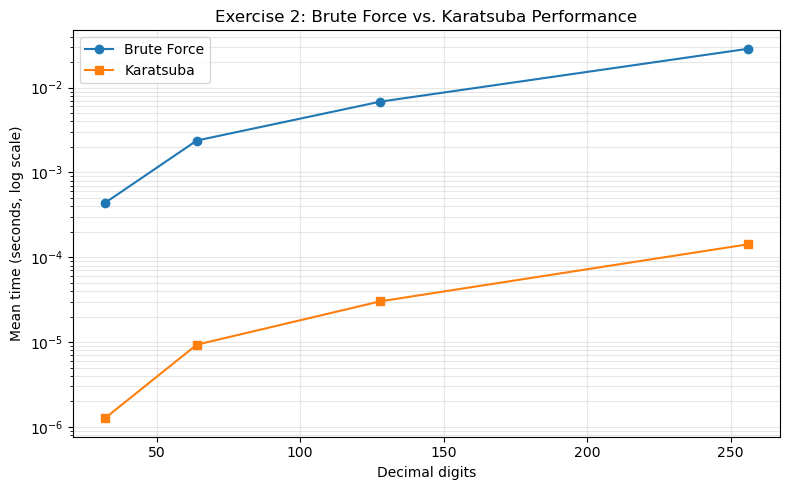

In [6]:
import random
import statistics
import time
import matplotlib.pyplot as plt

SEED = 20260907
DIGIT_SIZES = [32, 64, 128, 256]
REPEATS = 3
CUTOFF = 32
rng = random.Random(SEED)


def brute_force(x, y):
  if x < 10 or y < 10:
    return x * y
  n = max(len(str(x)), len(str(y)))
  m = n // 2
  power = 10**m
  a, b = divmod(x, power)
  c, d = divmod(y, power)
  ac = brute_force(a, c)
  ad = brute_force(a, d)
  bc = brute_force(b, c)
  bd = brute_force(b, d)
  return ac * 10 ** (2 * m) + (ad + bc) * 10**m + bd


def karatsuba(x, y, cutoff=CUTOFF):
  n = max(len(str(x)), len(str(y)))
  if n <= cutoff:
    return x * y
  m = n // 2
  power = 10**m
  a, b = divmod(x, power)
  c, d = divmod(y, power)
  p = karatsuba(a, c, cutoff)
  q = karatsuba(b, d, cutoff)
  r = karatsuba(a + b, c + d, cutoff)
  return p * 10 ** (2 * m) + (r - p - q) * power + q


def mean_time(f, x, y, repeats=REPEATS):
  values = []
  answer = None
  for _ in range(repeats):
    start = time.perf_counter()
    answer = f(x, y)
    values.append(time.perf_counter() - start)
  return statistics.mean(values), answer


tb_list, tk_list = [], []
for n in DIGIT_SIZES:
  x = rng.randint(10 ** (n - 1), 10**n - 1)
  y = rng.randint(10 ** (n - 1), 10**n - 1)
  tb, _ = mean_time(brute_force, x, y)
  tk, _ = mean_time(karatsuba, x, y)
  tb_list.append(tb)
  tk_list.append(tk)
  ratio = tb / tk
  print(
      f"{n:3d} digits | Brute: {tb:.6e}s | Karatsuba: {tk:.6e}s | Ratio (t_B/t_K):"
      f" {ratio:.2f}"
  )
  if ratio > 1:
    print(f"  -> Ratio is greater than 1 for {n} digits.")

plt.figure(figsize=(8, 5))
plt.plot(DIGIT_SIZES, tb_list, "o-", label="Brute Force")
plt.plot(DIGIT_SIZES, tk_list, "s-", label="Karatsuba")
plt.yscale("log")
plt.xlabel("Decimal digits")
plt.ylabel("Mean time (seconds, log scale)")
plt.title("Exercise 2: Brute Force vs. Karatsuba Performance")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()